## This notebook is for analysing the frequency of tags in the coarse tagset PoS tagger for Scottish Gaelic. 

In [1]:
# imports
import json
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd

### Per tag frequencies

Load the metrics

In [3]:
metrics_file = Path("../results/coarse_full_evaluation_metrics.json")

with metrics_file.open("r", encoding="utf-8") as f:
    metrics = json.load(f)

per_tag = metrics["per_tag"]

print(f"Number of tags: {len(per_tag)}")
print(f"Test documents: {metrics['n_documents']}")
print(f"Aligned tokens: {metrics['n_aligned_tokens']}")

Number of tags: 40
Test documents: 9
Aligned tokens: 9866


Record frequencies per tag

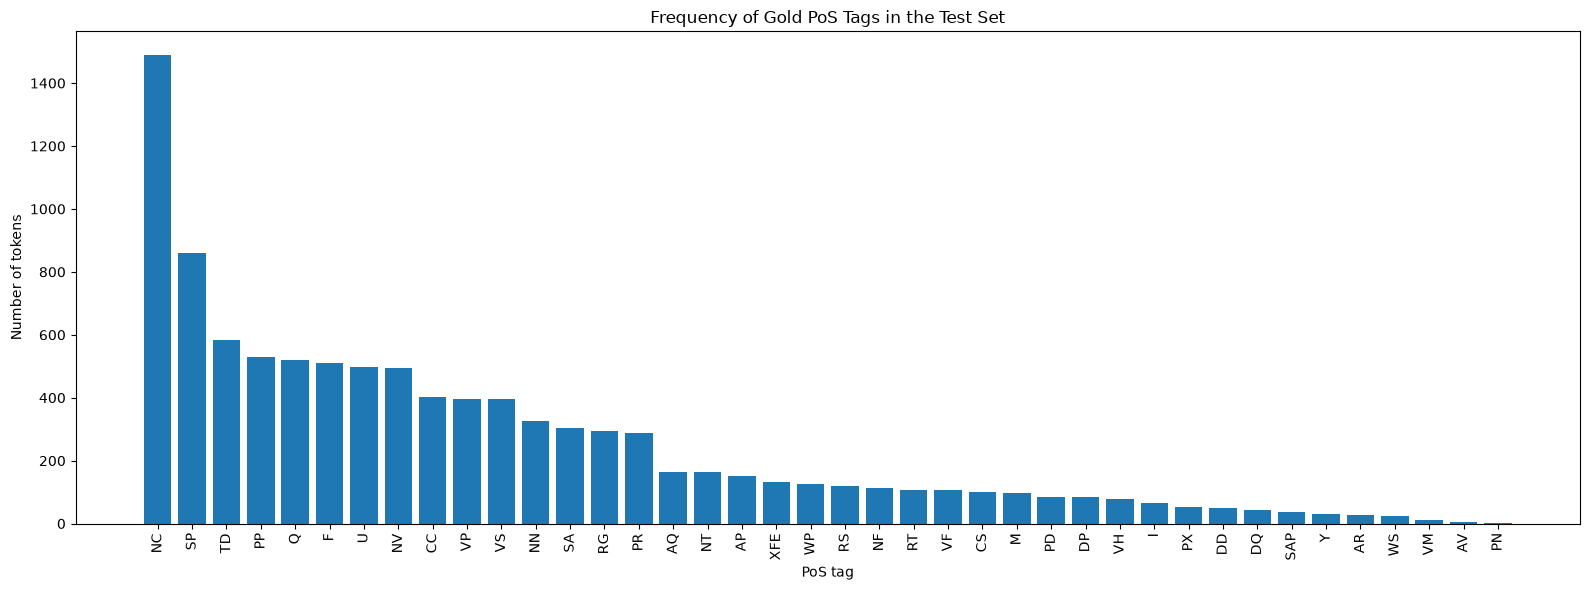

In [4]:
tags = list(per_tag.keys())
frequencies = [
    per_tag[tag]["support"] for tag in tags
]

# Sort from most frequent to least frequent
sorted_data = sorted(
    zip(tags, frequencies),
    key=lambda item: item[1],
    reverse=True
)

tags, frequencies = zip(*sorted_data)

plt.figure(figsize=(16, 6))
plt.bar(tags, frequencies)

plt.xlabel("PoS tag")
plt.ylabel("Number of tokens")
plt.title("Frequency of Gold PoS Tags in the Test Set")

plt.xticks(rotation=90)
plt.tight_layout()

plt.show()

Save the graph

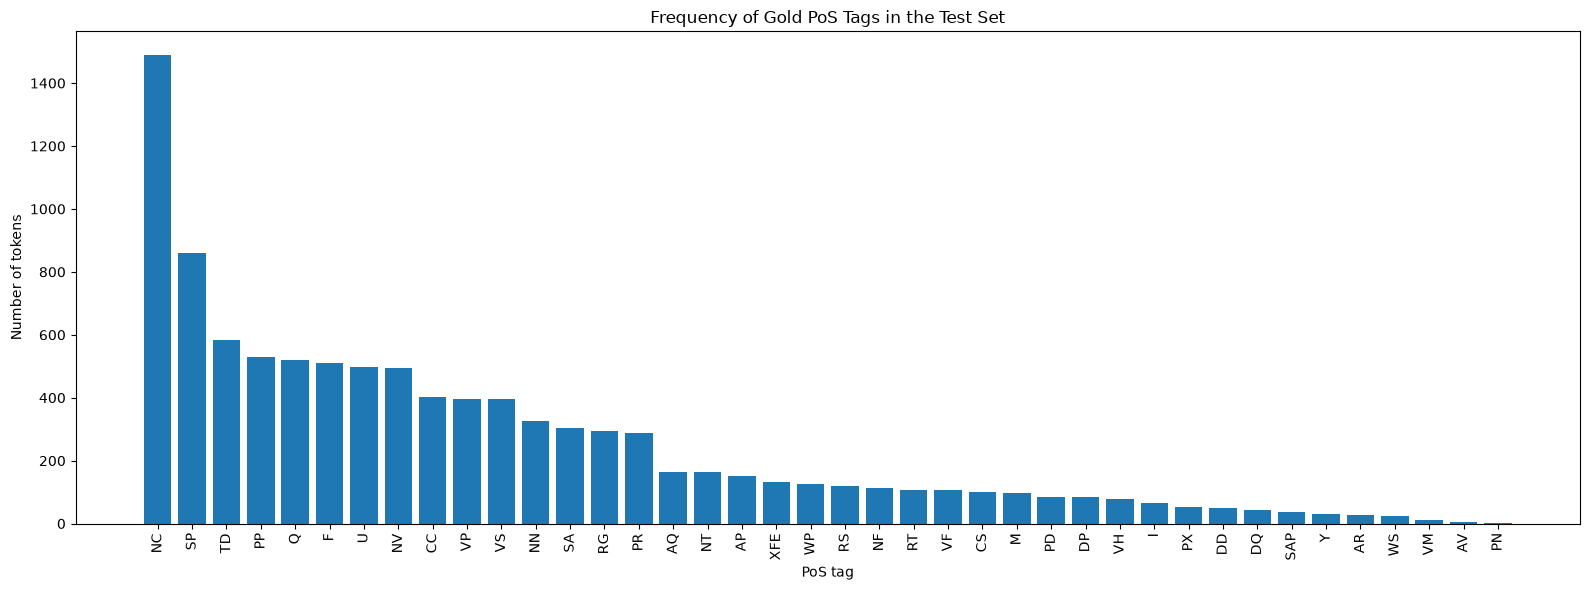

Saved to: C:\Users\peter\Documents\PhD_Project\Gaelic_SpaCy_Q1_2026\results\coarse_tag_frequency.png


In [5]:
output_file = Path("../results/coarse_tag_frequency.png")

plt.figure(figsize=(16, 6))
plt.bar(tags, frequencies)

plt.xlabel("PoS tag")
plt.ylabel("Number of tokens")
plt.title("Frequency of Gold PoS Tags in the Test Set")

plt.xticks(rotation=90)
plt.tight_layout()

plt.savefig(output_file, dpi=300, bbox_inches="tight")
plt.show()

print(f"Saved to: {output_file.resolve()}")

### Per-tag f1 scores (20 lowest)

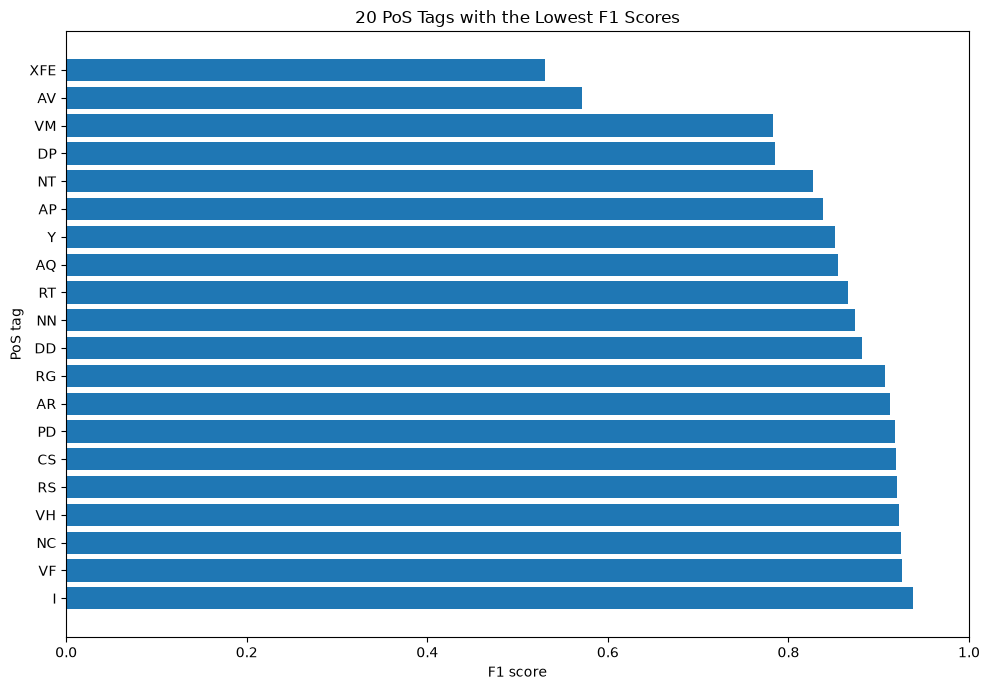

In [6]:
tag_metrics = [
    (tag, values)
    for tag, values in per_tag.items()
    if values["support"] > 0
]

# Lowest F1 first
tag_metrics = sorted(
    tag_metrics,
    key=lambda item: item[1]["f1"]
)[:20] # 20 lowest

tags = [tag for tag, _ in tag_metrics]
f1_scores = [values["f1"] for _, values in tag_metrics]

plt.figure(figsize=(10, 7))
plt.barh(tags, f1_scores)
plt.xlabel("F1 score")
plt.ylabel("PoS tag")
plt.title("20 PoS Tags with the Lowest F1 Scores")
plt.xlim(0, 1)
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig("../results/coarse_lowest_f1.png",
            dpi=300, bbox_inches="tight")
plt.show()


### Per-tag accuracy (20 lowest)

In [ ]:
tag_metrics = [
    (tag, values)
    for tag, values in per_tag.items()
    if values["support"] > 0
]

# Lowest F1 first
tag_metrics = sorted(
    tag_metrics,
    key=lambda item: item[1][""] # accuracy
)[:20] # 20 lowest

tags = [tag for tag, _ in tag_metrics]
f1_scores = [values["f1"] for _, values in tag_metrics]

plt.figure(figsize=(10, 7))
plt.barh(tags, f1_scores)
plt.xlabel("F1 score")
plt.ylabel("PoS tag")
plt.title("20 PoS Tags with the Lowest F1 Scores")
plt.xlim(0, 1)
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig("../results/coarse_lowest_f1.png",
            dpi=300, bbox_inches="tight")
plt.show()


### Tag frequency against f1 scores

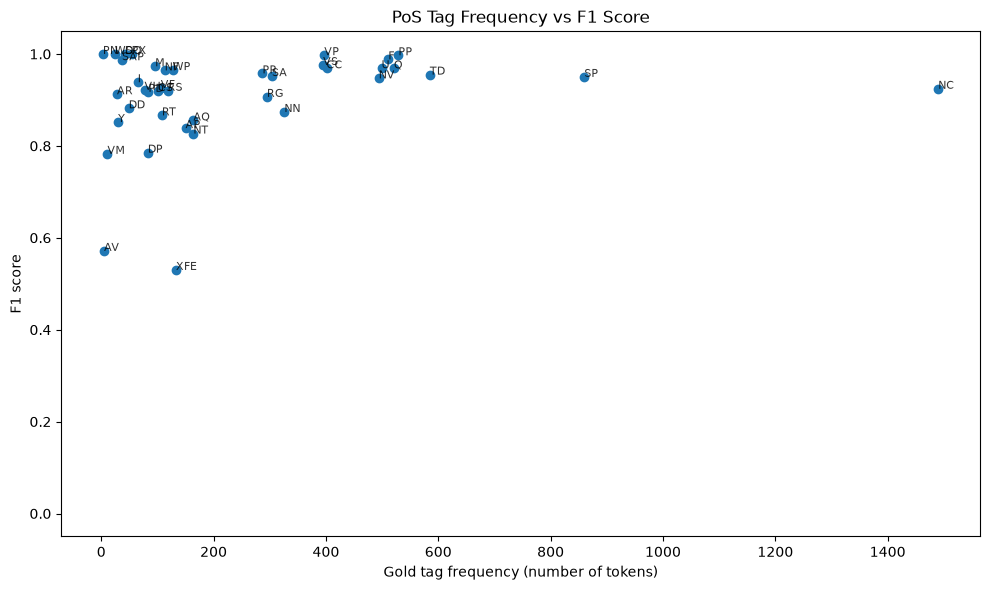

In [7]:

import matplotlib.pyplot as plt

supports = [
    values["support"] for values in per_tag.values()
]
f1_scores = [
    values["f1"] for values in per_tag.values()
]
tags = list(per_tag.keys())

plt.figure(figsize=(10, 6))
plt.scatter(supports, f1_scores)

# Label the individual tags
for tag, support, f1 in zip(tags, supports, f1_scores):
    plt.annotate(tag, (support, f1),
                 fontsize=8, alpha=0.8)

plt.xlabel("Gold tag frequency (number of tokens)")
plt.ylabel("F1 score")
plt.title("PoS Tag Frequency vs F1 Score")
plt.ylim(-0.05, 1.05)
plt.tight_layout()
plt.savefig("../results/coarse_frequency_vs_f1.png",
            dpi=300, bbox_inches="tight")
plt.show()

### Precision against recall

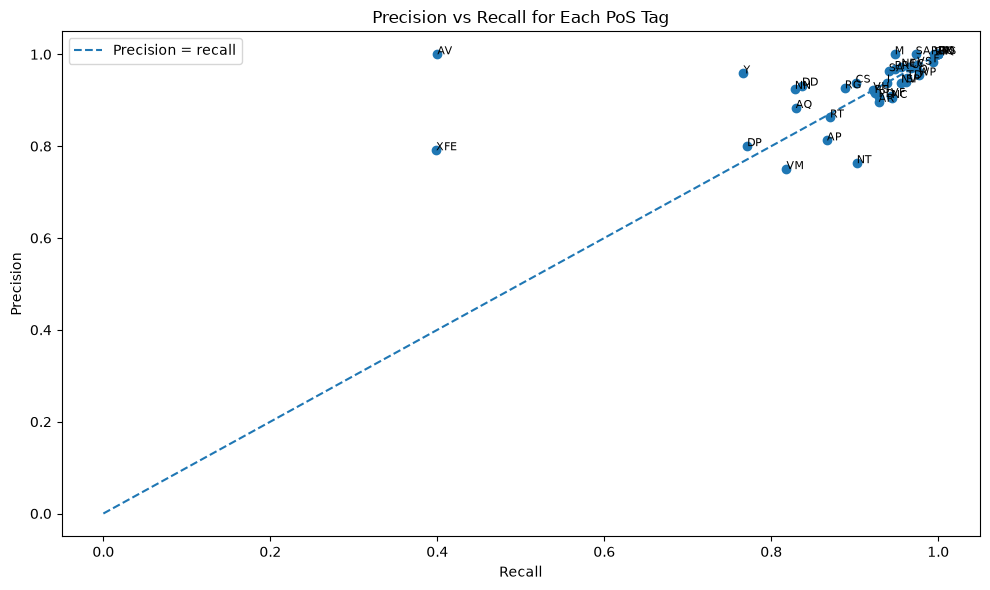

In [9]:

import matplotlib.pyplot as plt

tags = list(per_tag.keys())
precision = [per_tag[t]["precision"] for t in tags]
recall = [per_tag[t]["recall"] for t in tags]

plt.figure(figsize=(10, 6))
plt.scatter(recall, precision)

for tag, r, p in zip(tags, recall, precision):
    plt.annotate(tag, (r, p), fontsize=8)

plt.plot([0, 1], [0, 1], linestyle="dashed",
         label="Precision = recall")

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision vs Recall for Each PoS Tag")
plt.xlim(-0.05, 1.05)
plt.ylim(-0.05, 1.05)
plt.legend()
plt.tight_layout()
plt.savefig("../results/coarse_precision_vs_recall.png",
            dpi=300, bbox_inches="tight")
plt.show()


### Full Confusion Matrix

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from pathlib import Path

# Load token-level predictions
df = pd.read_csv("../results/coarse_full_predictions.csv")

# Keep only tokens that were aligned
aligned = df[df["alignment_status"] == "aligned"].copy()

# Keep gold and predicted tags
y_true = aligned["gold_tag"]
y_pred = aligned["predicted_tag"]

# Print
print(f"Aligned tokens: {len(aligned)}")
print(f"Correct predictions: {(y_true == y_pred).sum()}")
print(f"Incorrect predictions: {(y_true != y_pred).sum()}")

Aligned tokens: 9866
Correct predictions: 9271
Incorrect predictions: 595


Generate the matrix

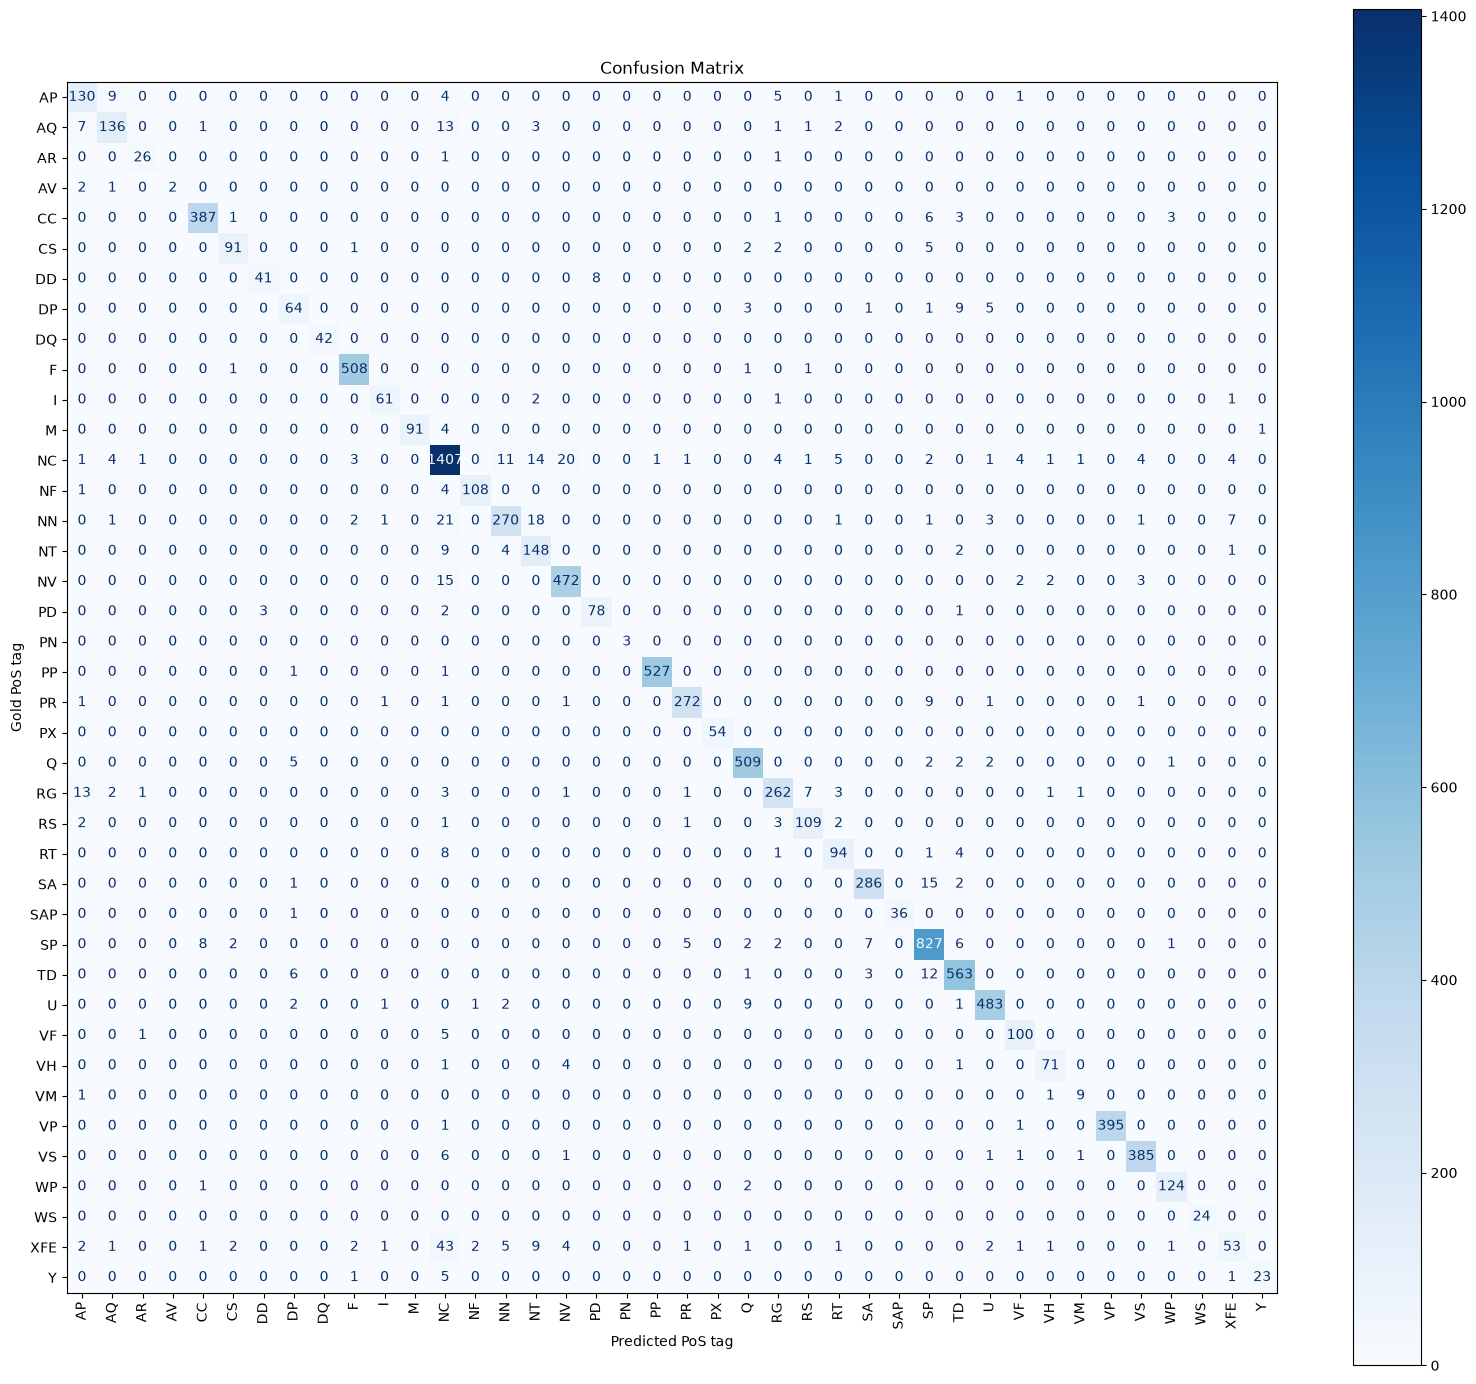

Saved to: C:\Users\peter\Documents\PhD_Project\Gaelic_SpaCy_Q1_2026\results\coarse_confusion_matrix.png


In [13]:
# Use the same tag order for both axes
labels = sorted(set(y_true) | set(y_pred))

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=labels
)

fig, ax = plt.subplots(figsize=(16, 14))

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
)

display.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=90,
    values_format="d",
    colorbar=True
)

ax.set_title("Confusion Matrix")
ax.set_xlabel("Predicted PoS tag")
ax.set_ylabel("Gold PoS tag")

plt.tight_layout()

# Save the figure
output_path = Path("../results/coarse_confusion_matrix.png")
plt.savefig(output_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Saved to: {output_path.resolve()}")

### Normalized matrix

Run instead of the above step

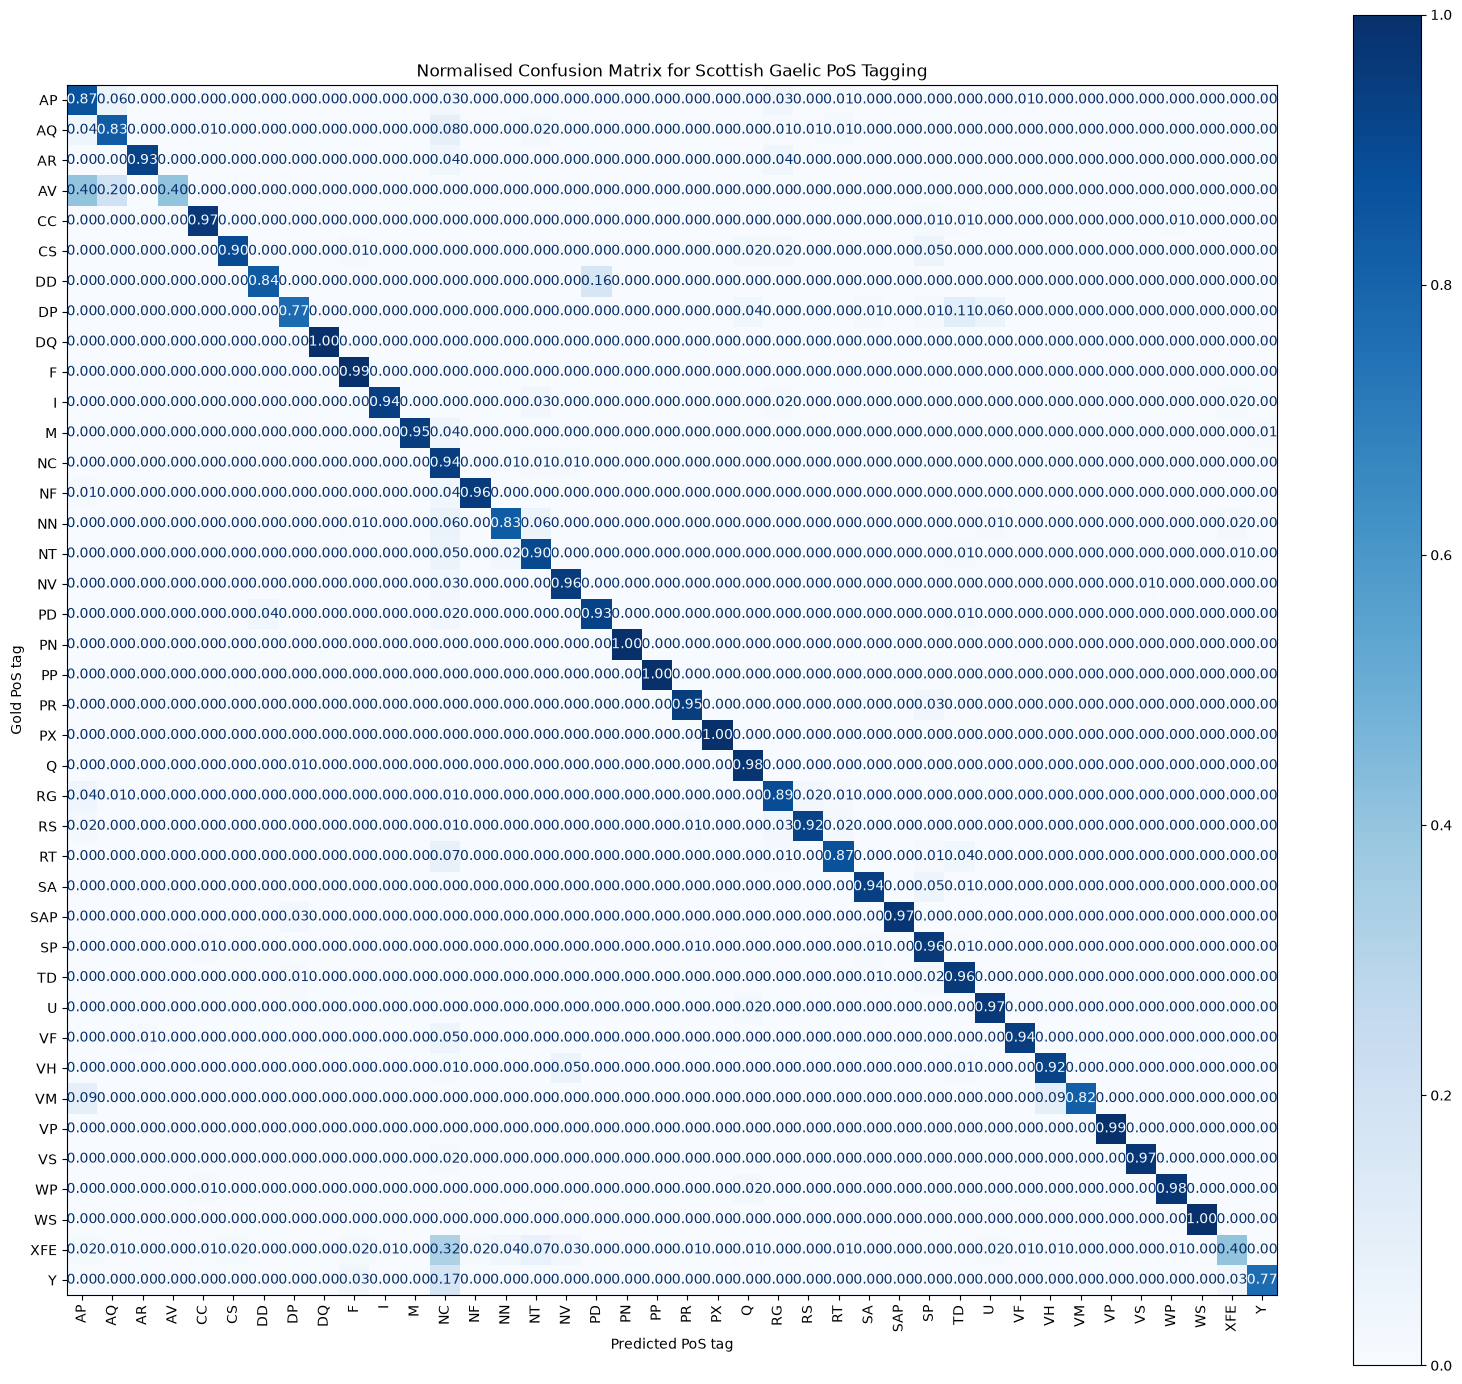

In [ ]:

cm_normalised = confusion_matrix(
    y_true,
    y_pred,
    labels=labels,
    normalize="true"
)

fig, ax = plt.subplots(figsize=(16, 14))

display = ConfusionMatrixDisplay(
    confusion_matrix=cm_normalised,
    display_labels=labels
)

display.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=90,
    values_format=".2f",
    colorbar=True
)

ax.set_title("Normalised Confusion Matrix")
ax.set_xlabel("Predicted PoS tag")
ax.set_ylabel("Gold PoS tag")

plt.tight_layout()
plt.savefig(
    "../results/coarse_confusion_matrix_normalised.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


- graph accuracy with different training sets (5, 10, 15, 20)
- English detection (false positives) check the context
- fix sentence columns
- all tests for fine-grained model

- common and uncommon tags
- context for errors
- Tokenization exceptions: where? Context.

- previous models from Lamb